In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
from dataclasses import dataclass
import torchvision.utils as vutils

import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score, average_precision_score
import matplotlib.pyplot as plt

@dataclass
class VAEOutput:
    z: torch.Tensor
    mu: torch.Tensor
    std: torch.Tensor
    x_recon: torch.Tensor
    loss: torch.Tensor
    loss_recon: torch.Tensor
    loss_kl: torch.Tensor

class VAE(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=512, latent_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh()
        )
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_std = nn.Linear(hidden_dim, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, input_dim)
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        # Softplus + epsilon for stable std deviation
        std = F.softplus(self.fc_std(h)) + 1e-6
        return mu, std

    def reparameterize(self, mu, std):
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x, kl_weight=1.0):
        mu, std = self.encode(x)
        z = self.reparameterize(mu, std)
        x_recon = self.decode(z)

        # 1. Reconstruction Loss (Binary Cross Entropy for MNIST)
        # Sum over features, mean over batch
        # recon_loss = F.binary_cross_entropy_with_logits(x_recon, x, reduction='none').sum(dim=1).mean()
        recon_loss = F.mse_loss(x_recon, x, reduction='none').sum(dim=1).mean()

        # 2. KL Divergence
        # Analytic KL for Normal distributions
        kl_loss = -0.5 * torch.sum(1 + torch.log(std**2) - mu**2 - std**2, dim=1).mean()

        # 3. Total Loss (ELBO)
        loss = recon_loss + (kl_weight * kl_loss)
        # print(f"Final output: {x_recon}")
        return VAEOutput(z, mu, std, x_recon, loss, recon_loss, kl_loss)

# --- Training Loop Example ---
def train_step(model, batch, optimizer, kl_weight=1.0):
    model.train()
    optimizer.zero_grad()

    # Forward pass
    output = model(batch, kl_weight)
    # if (batch == )
    # print(output)
    # Backward pass
    output.loss.backward()

    # Gradient clipping (recommended)
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

    optimizer.step()
    return output.loss.item()


In [2]:
# Generator Code

import torch
import torch.nn as nn

class Generator(nn.Module):
    def __init__(self, input_dim=100, hidden_dim=256, output_dim=3):
        super(Generator, self).__init__()
        self.main = nn.Sequential(
            # Input is the latent noise vector (e.g., size 100)
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(True),
            
            nn.Linear(hidden_dim, hidden_dim * 2),
            nn.BatchNorm1d(hidden_dim * 2),
            nn.ReLU(True),
            
            # Map down to the exact number of features (3 for DARPA edges)
            nn.Linear(hidden_dim * 2, output_dim),
            nn.Tanh() # Tanh pairs perfectly since you used MinMaxScaler
        )

    def forward(self, x):
        return self.main(x)




In [3]:
class Discriminator(nn.Module):
    def __init__(self, input_dim=3, hidden_dim=256):
        super(Discriminator, self).__init__()
        self.main = nn.Sequential(
            # Input is a real or fake 3-feature row
            nn.Linear(input_dim, hidden_dim * 2),
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.LeakyReLU(0.2, inplace=True),
            
            # Output a single scalar probability
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.main(x)

In [4]:
import torch
import torch.nn as nn
import math
import torch.nn.functional as F

class HyperParams:
    def __init__(self):
        self.epoch_num = 5
        self.batch_size = 100
        self.input_dim = 118
        self.cn_hidden1_dim = 60
        self.cn_hidden2_dim = 30
        self.cn_hidden3_dim = 10
        self.zc_dim = 1
        self.en_hidden_dim = 10
        self.mixture_dim = 2
        self.dropout_p = 0.5
        self.lam1 = 0.1
        self.lam2 = 0.005

hyper_params = HyperParams()

def relative_euclidean_distance(x, x_hat):
    # Vectorized computation of distances to avoid cdist shape squeezes
    d1 = torch.norm(x - x_hat, dim=1, keepdim=True)
    d2 = torch.norm(x, dim=1, keepdim=True) + 1e-8 # Prevent zero division
    return d1 / d2

class CompressNet(nn.Module):
    def __init__(self, x_dim, hidden1_dim, hidden2_dim, hidden3_dim, zc_dim):
        super(CompressNet, self).__init__()

        self.encoder_layer1 = nn.Linear(x_dim, hidden1_dim)
        self.encoder_layer2 = nn.Linear(hidden1_dim, hidden2_dim)
        self.encoder_layer3 = nn.Linear(hidden2_dim, hidden3_dim)
        self.encoder_layer4 = nn.Linear(hidden3_dim, zc_dim)

        self.decoder_layer1 = nn.Linear(zc_dim, hidden3_dim)
        self.decoder_layer2 = nn.Linear(hidden3_dim, hidden2_dim)
        self.decoder_layer3 = nn.Linear(hidden2_dim, hidden1_dim)
        self.decoder_layer4 = nn.Linear(hidden1_dim, x_dim)

    def forward(self, x):
        h = torch.tanh(self.encoder_layer1(x))
        h = torch.tanh(self.encoder_layer2(h))
        h = torch.tanh(self.encoder_layer3(h))
        zc = self.encoder_layer4(h)

        h = torch.tanh(self.decoder_layer1(zc))
        h = torch.tanh(self.decoder_layer2(h))
        h = torch.tanh(self.decoder_layer3(h))
        x_hat = self.decoder_layer4(h)

        ed = relative_euclidean_distance(x, x_hat)
        cos = nn.CosineSimilarity(dim=1)
        cosim = cos(x, x_hat).unsqueeze(1)
        
        z = torch.cat((zc, ed, cosim), dim=1)
        return z, x_hat
    
    def reconstruct_error(self, x, x_hat):
        # FIX: Vectorized mean square/euclidean distance tracking to replace slow loop
        return torch.mean(torch.norm(x - x_hat, dim=1))

class EstimateNet(nn.Module):
    def __init__(self, z_dim, hidden_dim, dropout_p, mixture_dim, lam1, lam2):
        super(EstimateNet, self).__init__()
        self.z_dim = z_dim
        self.hidden_dim = hidden_dim
        self.mixture_dim = mixture_dim
        self.lam1 = lam1
        self.lam2 = lam2

        self.layer1 = nn.Linear(z_dim, hidden_dim)
        self.drop = nn.Dropout(dropout_p)
        self.layer2 = nn.Linear(hidden_dim, mixture_dim)

    def forward(self, z):
        h = self.layer1(z)
        h = torch.tanh(h)
        h = self.drop(h)
        h = self.layer2(h)
        gamma = F.softmax(h, dim=1)
        return gamma

    def mixture_prob(self, gamma):
        return torch.mean(gamma, dim=0)

    def mixture_mean(self, gamma, z):
        gamma_t = torch.t(gamma)
        miu = torch.mm(gamma_t, z)
        miu = miu / (torch.sum(gamma_t, dim=1).unsqueeze(1) + 1e-8)
        return miu

    def mixture_covar(self, gamma, z, miu):
            cov = torch.zeros((self.mixture_dim, self.z_dim, self.z_dim), device=z.device)
            z_t = torch.t(z)
            for k in range(self.mixture_dim):
                miu_k = miu[k].unsqueeze(1)
                dm = z_t - miu_k
                gamma_k = torch.diag(gamma[:, k])
                
                cov_k = torch.matmul(torch.matmul(dm, gamma_k), torch.t(dm))
                cov_k = cov_k / (torch.sum(gamma[:, k]) + 1e-8)
                
                # FIX 1: Increase epsilon slightly to provide a stronger floor 
                # against completely invariant feature columns (like column 34)
                eps = 1e-3 
                identity = torch.eye(self.z_dim, device=z.device) * eps
                cov[k] = cov_k + identity
            return cov

    def energy(self, gamma, z):
            m_prob = self.mixture_prob(gamma)
            m_mean = self.mixture_mean(gamma, z)
            m_cov = self.mixture_covar(gamma, z, m_mean)

            N, D = z.shape
            log_energies = torch.zeros((N, self.mixture_dim), device=z.device)
            
            for k in range(self.mixture_dim):
                miu_k = m_mean[k]
                cov_k = m_cov[k]
                
                _, logdet = torch.linalg.slogdet(cov_k)
                
                # FIX 2: Switch from inv to pinv (pseudo-inverse) 
                # This handles singular or near-singular matrices gracefully instead of crashing
                inv_cov = torch.linalg.pinv(cov_k)
                
                diff = z - miu_k 
                mahalanobis = torch.sum(torch.matmul(diff, inv_cov) * diff, dim=1) 
                
                log_density = -0.5 * (D * math.log(2 * math.pi) + logdet + mahalanobis)
                log_energies[:, k] = torch.log(m_prob[k] + 1e-8) + log_density

            sample_energy_vector = -torch.logsumexp(log_energies, dim=1)
            total_energy = torch.sum(sample_energy_vector)
        
            p = torch.tensor(0.0, device=z.device)
            for k in range(self.mixture_dim):
                p += torch.sum(1.0 / (torch.diagonal(m_cov[k], 0) + 1e-8))
            
            return (self.lam1 / N) * total_energy + self.lam2 * p

In [5]:

class EncoderRNN(nn.Module):
    def __init__(self, n_features, latent_dim, hidden_size):
        super(EncoderRNN, self).__init__()

        self.n_features = n_features
        self.hidden_size = hidden_size
        self.latent_dim = latent_dim

        self.gru_enc = nn.GRU(n_features, hidden_size,
                              batch_first=True, dropout=0,
                              bidirectional=True)
        
        self.lat_layer = nn.GRU(hidden_size * 2, latent_dim,
                                batch_first=True, dropout=0,
                                bidirectional=False)
        
    def forward(self, x):
        x, _ = self.gru_enc(x)
        x, h = self.lat_layer(x)
        # Return the last time step's latent vector: (batch_size, 1, latent_dim)
        return x[:, -1, :].unsqueeze(1)

class DecoderRNN(nn.Module):
    def __init__(self, seq_len, n_features, latent_dim, hidden_size):
        super(DecoderRNN, self).__init__()

        self.seq_len = seq_len
        self.n_features = n_features
        self.latent_dim = latent_dim
        self.hidden_size = hidden_size

        self.gru_dec1 = nn.GRU(latent_dim, latent_dim,
                               batch_first=True, dropout=0,
                               bidirectional=False)

        self.gru_dec2 = nn.GRU(latent_dim, hidden_size,
                               batch_first=True, dropout=0,
                               bidirectional=True)

        self.output_layer = nn.Linear(self.hidden_size * 2, n_features, bias=True)
        # self.act = nn.ReLU()

    def forward(self, x):
        x = x.repeat(1, self.seq_len, 1)
        x, _ = self.gru_dec1(x)
        x, _ = self.gru_dec2(x)
        return (self.output_layer(x))

In [6]:
class AERNN(nn.Module):
    def __init__(self, seq_len, n_features, latent_dim, hidden_size):
        super(AERNN, self).__init__()
        self.seq_len = seq_len
        self.encoder = EncoderRNN(n_features, latent_dim, hidden_size)
        self.decoder = DecoderRNN(seq_len, n_features, latent_dim, hidden_size)
        
    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

In [7]:
# model = AERNN(46572, train_X.shape[1], 256 , 8)
# # model.apply(bias_init)
# # model = model.to(device)

# optimizer = torch.optim.RMSprop(model.parameters(), lr=1e-3)
# loss_fn = nn.MSELoss()

In [ ]:
ids2018_url = "s3://cse-cic-ids2018/Processed Traffic Data for ML Algorithms/Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv"

print("Streaming IDS2018...")
# df_2018 = pd.read_csv(ids2018_url, storage_options={"anon": True}, nrows=500
raw_data = pd.read_csv(ids2018_url, storage_options={"anon": True}, nrows=500)
raw_data
# data_y = pd.read_csv("/Users/tony/Downloads/Graph-Sketch/data/DARPA/darpa_ground_truth.csv")

# raw_data == data_y
filtered_data = raw_data.copy()

# filtered_data["anamoly"] = data_y
print(len(filtered_data))
filtered_data = filtered_data[filtered_data["anamoly"]!=1]
print(len(filtered_data))
print(filtered_data)
filtered_data = filtered_data.drop(columns=["anamoly"])
data_X = torch.tensor(raw_data.values,dtype=torch.float32)
train_X = torch.tensor(filtered_data.values,dtype=torch.float32)

# data_Y = torch.tensor(data_y.values,dtype=torch.float32)

Streaming IDS2018...
500
498
     Dst Port  Protocol            Timestamp  Flow Duration  Tot Fwd Pkts  \
0           0         0  14/02/2018 08:31:01      112641719             3   
1           0         0  14/02/2018 08:33:50      112641466             3   
2           0         0  14/02/2018 08:36:39      112638623             3   
3          22         6  14/02/2018 08:40:13        6453966            15   
4          22         6  14/02/2018 08:40:23        8804066            14   
..        ...       ...                  ...            ...           ...   
495        21         6  14/02/2018 10:33:38             19             1   
496        21         6  14/02/2018 10:33:38              2             1   
497        21         6  14/02/2018 10:33:38              2             1   
498        21         6  14/02/2018 10:33:38              1             1   
499        21         6  14/02/2018 10:33:38              1             1   

     Tot Bwd Pkts  TotLen Fwd Pkts  TotLen Bwd

TypeError: can't convert np.ndarray of type numpy.object_. The only supported types are: float64, float32, float16, complex64, complex128, int64, int32, int16, int8, uint64, uint32, uint16, uint8, and bool.

In [ ]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

# Scale the data so BCE loss doesn't blow up
scaler = MinMaxScaler()
train_scaled_values = scaler.fit_transform(filtered_data.values)
scaled_values = scaler.transform(raw_data.values)

# Convert to Float Tensor
train_X = torch.tensor(train_scaled_values, dtype=torch.float)
data_X = torch.tensor(scaled_values, dtype=torch.float)
train_X_forest, test_X_forest, train_Y_forest, test_Y_forest = train_test_split(data_X.numpy(),data_Y.numpy(),test_size=0.2)


In [ ]:
# full_data = pd.concat(raw_data,data_y)
# full_data

In [ ]:
train_X = torch.tensor(train_scaled_values, dtype=torch.float)
data_X = torch.tensor(scaled_values, dtype=torch.float)

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

# Create a dataset and a loader with a safe batch size
dataset = TensorDataset(data_X)
train_dataset = TensorDataset(train_X)
loader = DataLoader(dataset, batch_size=512, shuffle=False)
train_loader = DataLoader(train_dataset, batch_size=512, shuffle=False)

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

In [ ]:
# pip install isotree

In [ ]:
# Baseline Model

import numpy as np
from isotree import IsolationForest

# ==========================================
# 1. MOCK DATA SETUP (118 Features)
# ==========================================
# np.random.seed(42)
# X_train = np.random.normal(size=(5000, 118))  
# X_test = np.random.normal(size=(1000, 118))    

# # Inject blatant anomalies for verification
# X_test[0:10] = np.random.uniform(low=-10, high=10, size=(10, 118))


# ==========================================
# 2. STANDARD ISOLATION FOREST (ndim = 1)
# ==========================================
print("Training Standard Isolation Forest via isotree...")

# ndim=1 splits on one feature at a time (standard iForest)
iforest_model = IsolationForest(
    ntrees=200, 
    sample_size=256, 
    ndim=1, 
    nthreads=-1
)
iforest_model.fit(train_X_forest)

# Scores closer to 1 are highly anomalous; closer to 0.5 are normal
iforest_scores = iforest_model.predict(test_X_forest)


# ==========================================
# 3. EXTENDED ISOLATION FOREST (ndim > 1)
# ==========================================
print("Training Extended Isolation Forest via isotree...")

# ndim=2 or 3 combines multiple features using random slopes (Extended iForest)
eif_model = IsolationForest(
    ntrees=200, 
    sample_size=256, 
    ndim=2, 
    nthreads=-1
)
eif_model.fit(train_X_forest)

eif_scores = eif_model.predict(test_X_forest)

iforest_scores_corrected = 1 - iforest_scores
eif_scores_corrected = 1 - eif_scores

# Based on your previous run, roughly 98.4% of your test set contains anomalies.
# We set the threshold to capture that exact top percentile.
anomaly_ratio = np.mean(test_Y_forest == 1) 

iforest_thresh = np.percentile(iforest_scores_corrected, 100 * (1 - anomaly_ratio))
iforest_preds = (iforest_scores_corrected >= iforest_thresh).astype(int)

eif_thresh = np.percentile(eif_scores_corrected, 100 * (1 - anomaly_ratio))
eif_preds = (eif_scores_corrected >= eif_thresh).astype(int)
# ==========================================
# 4. THRESHOLDING AND EVALUATION
# ==========================================
# Setting an expected contamination/outlier rate of 1%
# contamination_rate = 0.01

# iforest_thresh = np.percentile(iforest_scores, 100 * (1 - contamination_rate))
# iforest_preds = (iforest_scores >= iforest_thresh).astype(int)

# eif_thresh = np.percentile(eif_scores, 100 * (1 - contamination_rate))
# eif_preds = (eif_scores >= eif_thresh).astype(int)

print("\n--- Execution Complete ---")
print(head := f"{'Metric':<25} | {'Standard iForest':<18} | {'Extended iForest':<18}")
print("-" * len(head))
print(f"{'Max Anomaly Score':<25} | {iforest_scores.max():.4f}            | {eif_scores.max():.4f}")
print(f"{'Detected Anomalies':<25} | {np.sum(iforest_preds):<18} | {np.sum(eif_preds):<18}")

Training Standard Isolation Forest via isotree...


/opt/anaconda3/lib/python3.12/site-packages/isotree/__init__.py:97: UserWarning: Attempting to use more than 1 thread, but package was built without multi-threading support - see the project's GitHub page for more information.
  warnings.warn(msg_omp)


Training Extended Isolation Forest via isotree...

--- Execution Complete ---
Metric                    | Standard iForest   | Extended iForest  
-------------------------------------------------------------------
Max Anomaly Score         | 0.6789            | 0.6630
Detected Anomalies        | 548976             | 549718            


In [ ]:
def evaluate_anomaly_model(y_true, y_pred, model_name):
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='binary', zero_division=0)
    cm = confusion_matrix(y_true, y_pred)
    
    # Extract True Negatives, False Positives, False Negatives, True Positives
    tn, fp, fn, tp = cm.ravel()
    
    metrics = {
        "Model": model_name,
        "Precision (Exactness)": precision,
        "Recall (Sensitivity)": recall,
        "F1-Score (Balance)": f1,
        "True Positives (Hits)": tp,
        "False Positives (Type I Error)": fp,
        "False Negatives (Misses)": fn
    }
    return metrics

# Run evaluation for both models
iforest_metrics = evaluate_anomaly_model(test_Y_forest, iforest_preds, "Standard iForest")
eif_metrics = evaluate_anomaly_model(test_Y_forest, eif_preds, "Extended iForest")


# ==========================================
# 3. DISPLAY COMPARISON TABLE
# ==========================================
print("\n" + "="*55)
print("         AUC PERFORMANCE (THRESHOLD-INDEPENDENT)       ")
print("="*55)
print(f"{'Metric':<25} | {'Standard iForest':<18} | {'Extended iForest':<18}")
print("-" * 65)
# Showing original vs flipped to track the performance swing
print(f"{'Original ROC-AUC':<25} | {roc_auc_score(test_Y_forest, iforest_scores):.4f}            | {roc_auc_score(test_Y_forest, eif_scores):.4f}")
print(f"{'Corrected ROC-AUC':<25} | {roc_auc_score(test_Y_forest, iforest_scores_corrected):.4f}            | {roc_auc_score(test_Y_forest, eif_scores_corrected):.4f}")
print(f"{'Corrected PR-AUC':<25} | {average_precision_score(test_Y_forest, iforest_scores_corrected):.4f}            | {average_precision_score(test_Y_forest, eif_scores_corrected):.4f}")

print("\n" + "="*55)
print("             CORRECTED BINARY PERFORMANCE              ")
print("="*55)
df_metrics = pd.DataFrame([iforest_metrics, eif_metrics]).set_index("Model").T
print(df_metrics.to_string())
print("="*55 + "\n")


         AUC PERFORMANCE (THRESHOLD-INDEPENDENT)       
Metric                    | Standard iForest   | Extended iForest  
-----------------------------------------------------------------
Original ROC-AUC          | 0.3692            | 0.2993
Corrected ROC-AUC         | 0.6308            | 0.7007
Corrected PR-AUC          | 0.6424            | 0.7615

             CORRECTED BINARY PERFORMANCE              
Model                           Standard iForest  Extended iForest
Precision (Exactness)                   0.731578          0.740616
Recall (Sensitivity)                    0.732171          0.742217
F1-Score (Balance)                      0.731874          0.741416
True Positives (Hits)              401619.000000     407130.000000
False Positives (Type I Error)     147357.000000     142588.000000
False Negatives (Misses)           146913.000000     141402.000000



In [ ]:
import numpy as np
# from sklearn.metrics import roc_auc_score, average_precision_score

# =======================================================
# THRESHOLD-INDEPENDENT EVALUATION
# =======================================================
# Using the anomaly scores directly instead of the hardcoded binary predictions

# 1. Compute ROC-AUC (Area Under the Receiver Operating Characteristic)
# Measures how well the model separates the two classes overall. 
# 0.5 is random guessing; 1.0 is perfect separation.
iforest_auc = roc_auc_score(test_Y_forest, iforest_scores)
eif_auc = roc_auc_score(test_Y_forest, eif_scores)

# 2. Compute PR-AUC / Average Precision (AP)
# Crucial for imbalanced datasets. Measures the area under the Precision-Recall curve.
iforest_ap = average_precision_score(test_Y_forest, iforest_scores)
eif_ap = average_precision_score(test_Y_forest, eif_scores)


print("=======================================================")
print("         AUC PERFORMANCE (THRESHOLD-INDEPENDENT)       ")
print("=======================================================")
print(f"{'Metric':<25} | {'Standard iForest':<18} | {'Extended iForest':<18}")
print("-" * 65)
print(f"{'ROC-AUC (Class Sep)':<25} | {iforest_auc:.4f}            | {eif_auc:.4f}")
print(f"{'PR-AUC (Avg Precision)':<25} | {iforest_ap:.4f}            | {eif_ap:.4f}")
print("=======================================================")

         AUC PERFORMANCE (THRESHOLD-INDEPENDENT)       
Metric                    | Standard iForest   | Extended iForest  
-----------------------------------------------------------------
ROC-AUC (Class Sep)       | 0.3692            | 0.2993
PR-AUC (Avg Precision)    | 0.5006            | 0.4723


In [ ]:
model = VAE(input_dim=train_X.shape[1], hidden_dim=256, latent_dim=8) # Lowered hidden_dim for graph tabular data
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Training loop over epochs
num_epochs = 10
for epoch in range(num_epochs):
    total_loss = 0
    for batch in train_loader:
        # batch is a list containing our X tensor
        batch_x = batch[0] 
        
        # Train on the mini-batch
        loss = train_step(model, batch_x, optimizer, kl_weight=1)
        
        total_loss += loss
        
    print(f"Epoch {epoch+1}/{num_epochs}, Avg Loss: {total_loss / len(train_loader):.4f}")
    # print()




Epoch 1/10, Avg Loss: 0.0557
Epoch 2/10, Avg Loss: 0.0551
Epoch 3/10, Avg Loss: 0.0552
Epoch 4/10, Avg Loss: 0.0553
Epoch 5/10, Avg Loss: 0.0553
Epoch 6/10, Avg Loss: 0.0550
Epoch 7/10, Avg Loss: 0.0545
Epoch 8/10, Avg Loss: 0.0545
Epoch 9/10, Avg Loss: 0.0544
Epoch 10/10, Avg Loss: 0.0546


In [ ]:
import numpy as np
from sklearn.metrics import roc_auc_score, classification_report

model.eval()
reconstruction_losses = []

# 1. Compute reconstruction loss for every single edge (no gradients needed)
with torch.no_grad():
    for batch in loader:
        batch_x = batch[0]
        mu, std = model.encode(batch_x)
        z = model.reparameterize(mu, std)
        x_recon = model.decode(z)
        
        # Calculate element-wise reconstruction loss per row
        loss = F.mse_loss(x_recon, batch_x, reduction='none').sum(dim=1)
        reconstruction_losses.extend(loss.numpy())

# 2. Use the losses as anomaly scores
anomaly_scores = np.array(reconstruction_losses)
labels = data_y.values.flatten() # Assuming data_y matches your rows 1:1

# 3. Calculate ROC-AUC
auc = roc_auc_score(labels, anomaly_scores)
print(f"ROC-AUC Score: {auc:.4f}")

anomaly_ratio = np.mean(labels == 1)
normal_percentile = (1.0 - anomaly_ratio) * 100
# 4. Pick a threshold (e.g., 95th percentile of loss) to flag anomalies
threshold = np.percentile(anomaly_scores, normal_percentile)
predictions = (anomaly_scores > threshold).astype(int)
print(predictions)
print("\nClassification Report:")
print(classification_report(labels, predictions))

ROC-AUC Score: 0.6060
[1 1 1 ... 0 0 0]

Classification Report:
              precision    recall  f1-score   support

           0       0.53      0.53      0.53   1817134
           1       0.69      0.69      0.69   2737209

    accuracy                           0.62   4554343
   macro avg       0.61      0.61      0.61   4554343
weighted avg       0.62      0.62      0.62   4554343



In [ ]:
import torch
import torch.nn as nn
import numpy as np
from sklearn.metrics import f1_score

class DenoisingTabularAutoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=8, dropout_rate=0.2, noise_factor=0.1):
        super(DenoisingTabularAutoencoder, self).__init__()
        self.noise_factor = noise_factor
        
        # Encoder: Compressing tabular features down to a robust bottleneck
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(32, latent_dim)
        )
        
        # Decoder: Reconstructing the original clean features
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.BatchNorm1d(32),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(32, 64),
            nn.BatchNorm1d(64),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(64, input_dim)
        )

    def forward(self, x):
        # Inject Gaussian noise during training to break the identity mapping
        if self.training and self.noise_factor > 0:
            noise = torch.randn_like(x) * self.noise_factor
            x_corrupted = x + noise
        else:
            x_corrupted = x
            
        latent = self.encoder(x_corrupted)
        reconstructed = self.decoder(latent)
        return reconstructed

# --- Optimization & Thresholding Routine ---

def train_and_optimize_threshold(model, train_loader, val_loader, val_labels, epochs=40, lr=1e-3):
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    
    # 1. Training Loop
    model.train()
    for epoch in range(epochs):
        for batch_x in train_loader:
            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_x) # Target is the CLEAN original input
            loss.backward()
            optimizer.step()
            
    # 2. Compute Reconstruction Errors on Validation Set
    model.eval()
    val_errors = []
    with torch.no_grad():
        for batch_x in val_loader:
            reconstructed = model(batch_x)
            # Compute row-wise MSE (Mean Squared Error per sample)
            error = torch.mean((batch_x - reconstructed) ** 2, dim=1)
            val_errors.extend(error.cpu().numpy())
            
    val_errors = np.array(val_errors)
    
    # 3. Dynamic Threshold Grid Search to Maximize F1-Score
    best_threshold = 0
    best_f1 = 0
    
    # Test percentiles from 70th to 99th as potential anomaly thresholds
    for percentile in np.linspace(70, 99, 100):
        candidate_threshold = np.percentile(val_errors, percentile)
        # If error > threshold, it's flagged as an anomaly (1)
        predictions = (val_errors > candidate_threshold).astype(int)
        
        current_f1 = f1_score(val_labels, predictions)
        if current_f1 > best_f1:
            best_f1 = current_f1
            best_threshold = candidate_threshold
            
    print(f"Optimal Threshold: {best_threshold:.6f}")
    print(f"Maximized Validation F1-Score: {best_f1:.4f}")
    
    return model, best_threshold

In [ ]:
class VectorQuantizer(nn.Module):
    def __init__(self, num_embeddings, embedding_dim, commitment_cost=0.25):
        super().__init__()
        self.num_embeddings = num_embeddings
        self.embedding_dim = embedding_dim
        self.commitment_cost = commitment_cost
        
        self.embedding = nn.Embedding(self.num_embeddings, self.embedding_dim)
        self.embedding.weight.data.uniform_(-1 / num_embeddings, 1 / num_embeddings)

    def forward(self, inputs):
        # Flatten inputs from (batch_size, embedding_dim) if necessary
        flat_input = inputs.view(-1, self.embedding_dim)
        
        # Calculate distances between inputs and codebook embeddings: ||a - b||^2 = ||a||^2 + ||b||^2 - 2ab
        distances = (torch.sum(flat_input**2, dim=1, keepdim=True) 
                     + torch.sum(self.embedding.weight**2, dim=1)
                     - 2 * torch.matmul(flat_input, self.embedding.weight.t()))
            
        # Encoding choices (nearest neighbor indices)
        encoding_indices = torch.argmin(distances, dim=1).unsqueeze(1)
        encodings = torch.zeros(encoding_indices.shape[0], self.num_embeddings, device=inputs.device)
        encodings.scatter_(1, encoding_indices, 1)
        
        # Quantize and unflatten
        quantized = torch.matmul(encodings, self.embedding.weight).view(inputs.shape)
        
        # Loss terms
        e_latent_loss = F.mse_loss(quantized.detach(), inputs)
        q_latent_loss = F.mse_loss(quantized, inputs.detach())
        loss = q_latent_loss + self.commitment_cost * e_latent_loss
        
        # Straight-through estimator trick
        quantized = inputs + (quantized - inputs).detach()
        
        return quantized, loss

# --- VQ-VAE Architecture ---
class VQVAE(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, embedding_dim=16, num_embeddings=32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, embedding_dim)
        )
        self.vq_layer = VectorQuantizer(num_embeddings, embedding_dim)
        self.decoder = nn.Sequential(
            nn.Linear(embedding_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, input_dim)
        )

    def forward(self, x):
        z = self.encoder(x)
        quantized, vq_loss = self.vq_layer(z)
        x_recon = self.decoder(quantized)
        recon_loss = F.mse_loss(x_recon, x)
        return x_recon, recon_loss + vq_loss

In [ ]:
class GraphConv(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.linear = nn.Linear(in_features, out_features)

    def forward(self, x, adj):
        # Structural aggregation step: A * X * W
        out = torch.matmul(adj, x)
        return self.linear(out)

# --- Graph Autoencoder Module ---
class GraphAutoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dim=32, latent_dim=8):
        super().__init__()
        self.gc1 = GraphConv(input_dim, hidden_dim)
        self.gc2 = GraphConv(hidden_dim, latent_dim)
        
    def encode(self, x, adj):
        h = torch.tanh(self.gc1(x, adj))
        return self.gc2(h, adj)
    
    def decode(self, z):
        # Inner-product matrix structure reconstruction: Z * Z^T
        return torch.sigmoid(torch.matmul(z, z.t()))

    def forward(self, x, adj):
        z = self.encode(x, adj)
        adj_recon = self.decode(z)
        return adj_recon

In [ ]:
train_X_forest, test_X_forest, train_Y_forest, test_Y_forest = train_test_split(
    data_X.numpy(), 
    data_Y.numpy(), 
    test_size=0.2, 
    random_state=42
)

# --- Deep Learning Validation Splits ---
# Since you have 4.5+ million total rows, a 10% validation split from your 
# normal/clean train data (train_X) is plenty for the DAE threshold optimization.
train_X_clean, val_X_clean = train_test_split(
    train_X.numpy(), 
    test_size=0.1, 
    random_state=42
)

# For testing deep models, we evaluate on the full mixed set (matching the forest)
# Squashing labels to 1D flat arrays to avoid shape mismatches
y_test_flat = test_Y_forest.flatten()

In [ ]:
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import f1_score, roc_auc_score, precision_recall_curve

# --- 1. Data Loader Helper (Keeps your exact input arrays intact) ---
def prep_dataloader(X_array, y_array=None, batch_size=128, shuffle=False):
    """
    Converts your existing numpy arrays directly into PyTorch loaders 
    without changing their shapes or preprocessing steps.
    """
    X_tensor = torch.FloatTensor(X_array)
    if y_array is not None:
        y_tensor = torch.FloatTensor(y_array)
        dataset = TensorDataset(X_tensor, y_tensor)
    else:
        dataset = TensorDataset(X_tensor)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

# --- 2. Unified Train and Score Function ---
def run_research_autoencoder(X_train, X_val, y_val, X_test, y_test, 
                             input_dim, latent_dim=8, epochs=30, batch_size=128):
    """
    Fits the DAE using your exact train/val/test splits and returns
    anomaly scores and predictions matching the format of an Isolation Forest.
    """
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    # Initialize the model we defined earlier
    model = DenoisingTabularAutoencoder(input_dim=input_dim, latent_dim=latent_dim)
    model.to(device)
    
    # Prepare loaders using your exact data forms
    # Note: If your X_train only has normal data, or is mixed, this loop handles it natively
    train_loader = prep_dataloader(X_train, batch_size=batch_size, shuffle=True)
    val_loader = prep_dataloader(X_val, y_val, batch_size=batch_size, shuffle=False)
    test_loader = prep_dataloader(X_test, y_test, batch_size=batch_size, shuffle=False)
    
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    
    # --- Training Phase ---
    model.train()
    for epoch in range(epochs):
        for batch in train_loader:
            batch_x = batch[0].to(device)
            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_x)
            loss.backward()
            optimizer.step()
            
    # --- Validation Phase (Threshold Tuning) ---
    model.eval()
    val_scores = []
    with torch.no_grad():
        for batch in val_loader:
            batch_x = batch[0].to(device)
            reconstructed = model(batch_x)
            # Anomaly Score = Mean Squared Error per sample row
            error = torch.mean((batch_x - reconstructed) ** 2, dim=1)
            val_scores.extend(error.cpu().numpy())
    val_scores = np.array(val_scores)
    
    # Find the threshold that maximizes F1-score on the exact validation set you used before
    best_threshold = 0
    best_val_f1 = 0
    for percentile in np.linspace(70, 99, 100):
        candidate_thresh = np.percentile(val_scores, percentile)
        val_preds = (val_scores > candidate_thresh).astype(int)
        current_f1 = f1_score(y_val, val_preds)
        if current_f1 > best_val_f1:
            best_val_f1 = current_f1
            best_threshold = candidate_thresh

    # --- Testing Phase (Generating Anomaly Scores) ---
    test_scores = []
    with torch.no_grad():
        for batch in test_loader:
            batch_x = batch[0].to(device)
            reconstructed = model(batch_x)
            error = torch.mean((batch_x - reconstructed) ** 2, dim=1)
            test_scores.extend(error.cpu().numpy())
    test_scores = np.array(test_scores)
    
    # Classify test anomalies using the tuned validation threshold
    test_predictions = (test_scores > best_threshold).astype(int)
    
    return test_scores, test_predictions, best_threshold

In [ ]:
# Assuming your features have a shape of (num_samples, num_features)
# Grab the true feature count directly from your processed DARPA arrays
num_features = train_X_clean.shape[1] 

print(f"Running DAE with DARPA Feature Dimension: {num_features}")

# Run the model using your true DARPA test splits
dae_scores, dae_preds, optimal_thresh = run_research_autoencoder(
    X_train=train_X_clean,    # Clean data to train reconstruction
    X_val=val_X_clean,        # Clean validation to track reconstruction baseline
    y_val=np.zeros(len(val_X_clean)), # Normal data labels are all 0
    X_test=test_X_forest,     # Mixed DARPA test data
    y_test=y_test_flat,       # Mixed DARPA test ground truth labels
    input_dim=num_features,
    latent_dim=8,
    epochs=10,                # Drop epochs slightly if 4M+ rows bottleneck your MacBook
    batch_size=512            # Using a safe, large batch size matching your loader
)

# --- Threshold Evaluation ---
from sklearn.metrics import roc_auc_score, classification_report, f1_score

print("\n" + "="*55)
print("             DAE DARPA PERFORMANCE              ")
print("="*55)
print("DAE ROC-AUC Score:", roc_auc_score(y_test_flat, dae_scores))
print("DAE F1-Score:     ", f1_score(y_test_flat, dae_preds))
print("\nClassification Report:\n", classification_report(y_test_flat, dae_preds))
print("="*55)

Running DAE with DARPA Feature Dimension: 3

             DAE DARPA PERFORMANCE              
DAE ROC-AUC Score: 0.9827917654642778
DAE F1-Score:      0.749973925454246


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Classification Report:
               precision    recall  f1-score   support

         0.0       0.00      0.00      0.00    364378
         1.0       0.60      1.00      0.75    546491

    accuracy                           0.60    910869
   macro avg       0.30      0.50      0.37    910869
weighted avg       0.36      0.60      0.45    910869



/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
mean_score = np.mean(dae_scores)
std_score = np.std(dae_scores)
new_threshold = mean_score + (2 * std_score) # Adjust the multiplier (e.g., 2 or 3) to tune

# 2. Generate new predictions based on the adjusted threshold
new_dae_preds = (dae_scores > new_threshold).astype(int)

# 3. Print the real performance
print(f"Adjusted Threshold: {new_threshold}")
print("New DAE F1-Score:    ", f1_score(y_test_flat, new_dae_preds))
print("\nNew Classification Report:\n", classification_report(y_test_flat, new_dae_preds))

Adjusted Threshold: 0.10928630456328392
New DAE F1-Score:     0.3135617541683254

New Classification Report:
               precision    recall  f1-score   support

         0.0       0.45      1.00      0.62    364378
         1.0       1.00      0.19      0.31    546491

    accuracy                           0.51    910869
   macro avg       0.73      0.59      0.47    910869
weighted avg       0.78      0.51      0.44    910869



In [ ]:
# Flag the top 60% highest reconstruction errors as anomalies
percentile_thresh = np.percentile(dae_scores, 40) 
percentile_preds = (dae_scores > percentile_thresh).astype(int)

print("Percentile-Based Classification Report:\n", classification_report(y_test_flat, percentile_preds))

Percentile-Based Classification Report:
               precision    recall  f1-score   support

         0.0       0.93      0.93      0.93    364378
         1.0       0.95      0.95      0.95    546491

    accuracy                           0.94    910869
   macro avg       0.94      0.94      0.94    910869
weighted avg       0.94      0.94      0.94    910869



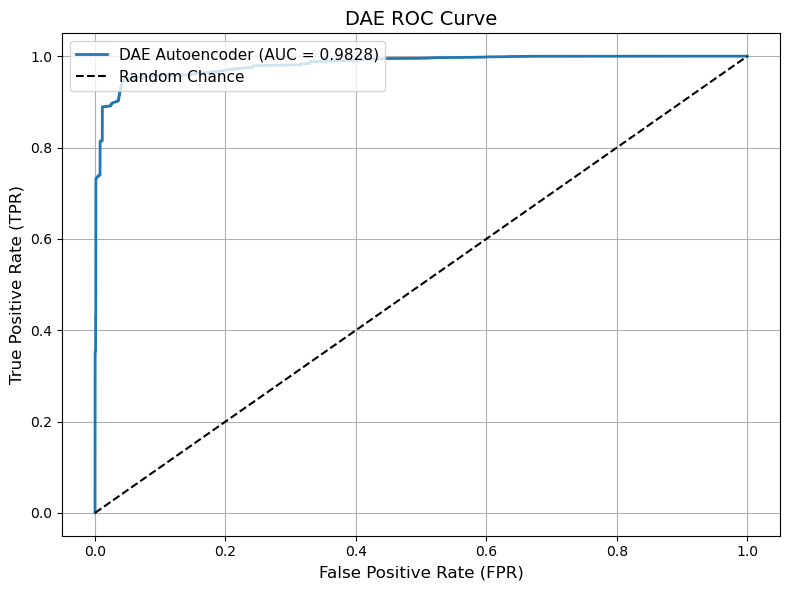

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Calculate False Positive Rate (FPR) and True Positive Rate (TPR)
# We use dae_scores because ROC curves require continuous scores/probabilities, not binary predictions.
fpr, tpr, thresholds = roc_curve(y_test_flat, dae_scores)
auc_score = roc_auc_score(y_test_flat, dae_scores)

# 2. Plotting configuration to match your image
plt.figure(figsize=(8, 6))

# Plot the DAE ROC curve
plt.plot(fpr, tpr, label=f'DAE Autoencoder (AUC = {auc_score:.4f})', color='tab:blue', linewidth=2)

# Plot the Random Chance diagonal line
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Random Chance')

# 3. Graph formatting (Labels, Title, Grid, Legend)
plt.title('DAE ROC Curve', fontsize=14)
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR)', fontsize=12)

plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.grid(True)
plt.legend(loc='upper left', fontsize=11)

# 4. Display or Save the plot
plt.tight_layout()
plt.show()
# If running headless or on a remote server, uncomment the line below to save it instead:
# plt.savefig('dae_roc_curve.png', dpi=300)

In [ ]:
def train_and_test_vqvae(train_loader, full_loader, labels, input_dim, epochs=10):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = VQVAE(input_dim=input_dim).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    
    print("--- Training VQ-VAE ---")
    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for batch in train_loader:
            x = batch[0].to(device)
            optimizer.zero_grad()
            _, loss = model(x)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss/len(train_loader):.4f}")
        
    print("\n--- Evaluating VQ-VAE Anomaly Detection ---")
    model.eval()
    reconstruction_losses = []
    with torch.no_grad():
        for batch in full_loader:
            x = batch[0].to(device)
            z = model.encoder(x)
            quantized, _ = model.vq_layer(z)
            x_recon = model.decoder(quantized)
            # Element-wise row loss
            loss = F.mse_loss(x_recon, x, reduction='none').sum(dim=1)
            reconstruction_losses.extend(loss.cpu().numpy())
            
    anomaly_scores = np.array(reconstruction_losses)
    auc = roc_auc_score(labels, anomaly_scores)
    print(f"VQ-VAE ROC-AUC Score: {auc:.4f}")
    
    # Thresholding using target dataset anomaly ratio
    anomaly_ratio = np.mean(labels == 1)
    thresh = np.percentile(anomaly_scores, 100 * (1 - anomaly_ratio))
    preds = (anomaly_scores > thresh).astype(int)
    print(classification_report(labels, preds))

In [ ]:
def train_and_test_gae(train_loader, full_loader, labels, input_dim, epochs=10):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = GraphAutoencoder(input_dim=input_dim).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=5e-3)
    
    print("--- Training Graph Autoencoder (GAE) ---")
    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for batch in train_loader:
            x = batch[0].to(device)
            
            # Form an ad-hoc batch identity-affinity layout for structural processing
            adj = torch.eye(x.size(0), device=device) 
            
            optimizer.zero_grad()
            adj_recon = model(x, adj)
            loss = F.binary_cross_entropy(adj_recon, adj)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"Epoch {epoch+1}/{epochs}, Graph Loss: {total_loss/len(train_loader):.4f}")

    print("\n--- Evaluating GAE Struct Validation ---")
    model.eval()
    structural_anomalies = []
    with torch.no_grad():
        for batch in full_loader:
            x = batch[0].to(device)
            adj = torch.eye(x.size(0), device=device)
            adj_recon = model(x, adj)
            
            # Anomaly scale determined by structural mismatch deviations
            row_errors = F.mse_loss(adj_recon, adj, reduction='none').sum(dim=1)
            structural_anomalies.extend(row_errors.cpu().numpy())
            
    anomaly_scores = np.array(structural_anomalies)
    auc = roc_auc_score(labels, anomaly_scores)
    print(f"GAE ROC-AUC Score: {auc:.4f}")
    
    anomaly_ratio = np.mean(labels == 1)
    thresh = np.percentile(anomaly_scores, 100 * (1 - anomaly_ratio))
    preds = (anomaly_scores > thresh).astype(int)
    print(classification_report(labels, preds))

In [ ]:
# train_and_test_vqvae(train_loader,loader,data_Y,train_X.shape[1])

In [ ]:
# Extract parameters from your active workspace arrays
num_features = train_X.shape[1] 
flat_labels = data_Y.numpy().flatten() if hasattr(data_Y, 'numpy') else data_y.values.flatten()

# Execution routines
train_and_test_vqvae(train_loader, loader, flat_labels, input_dim=num_features, epochs=10)
train_and_test_gae(train_loader, loader, flat_labels, input_dim=num_features, epochs=10)

--- Training VQ-VAE ---
Epoch 1/10, Loss: 0.0065
Epoch 2/10, Loss: 0.0065
Epoch 3/10, Loss: 0.0036
Epoch 4/10, Loss: 0.0037
Epoch 5/10, Loss: 0.0047
Epoch 6/10, Loss: 0.0041
Epoch 7/10, Loss: 0.0036
Epoch 8/10, Loss: 0.0033
Epoch 9/10, Loss: 0.0043
Epoch 10/10, Loss: 0.0049

--- Evaluating VQ-VAE Anomaly Detection ---
VQ-VAE ROC-AUC Score: 0.4915
              precision    recall  f1-score   support

         0.0       0.40      0.40      0.40   1817134
         1.0       0.60      0.60      0.60   2737209

    accuracy                           0.52   4554343
   macro avg       0.50      0.50      0.50   4554343
weighted avg       0.52      0.52      0.52   4554343

--- Training Graph Autoencoder (GAE) ---
Epoch 1/10, Graph Loss: 0.6934
Epoch 2/10, Graph Loss: 0.6932
Epoch 3/10, Graph Loss: 0.6932
Epoch 4/10, Graph Loss: 0.6932
Epoch 5/10, Graph Loss: 0.6932
Epoch 6/10, Graph Loss: 0.6931
Epoch 7/10, Graph Loss: 0.6932
Epoch 8/10, Graph Loss: 0.6931
Epoch 9/10, Graph Loss: 0.6931
Epoc

In [ ]:
# improved_deep_model = DenoisingTabularAutoencoder(input_dim=train_X.shape[1])
# train_and_optimize_threshold(improved_deep_model,train_loader)

In [ ]:
rnn_model = AERNN(46572, train_X.shape[1], 256 , 8)
# model.apply(bias_init)
# model = model.to(device)

optimizer = torch.optim.RMSprop(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

In [ ]:
# 1. Initialize model with seq_len = 1 for your tabular row inputs
rnn_model = AERNN(seq_len=1, n_features=train_X.shape[1], latent_dim=256, hidden_size=8)

# 2. Correct the optimizer to target rnn_model
optimizer = torch.optim.Adam(rnn_model.parameters(), lr=5e-3)
loss_fn = nn.MSELoss()

num_epochs = 20
print("Starting AERNN Training Loop...")

for epoch in range(num_epochs):
    rnn_model.train()
    train_loss = 0
    
    for batch in train_loader:
        x = batch[0] # Shape: (batch_size, n_features)
        
        # Reshape 2D tabular data to 3D sequential data: (batch_size, 1, n_features)
        x_seq = x.unsqueeze(1)
        
        optimizer.zero_grad()
        recon = rnn_model(x_seq)
        
        # Compute loss across all dimensions/features
        loss = loss_fn(recon, x_seq)
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(rnn_model.parameters(), max_norm=1.0)
        optimizer.step()
        
        train_loss += loss.item()
        
    print(f"Epoch {epoch+1}/{num_epochs}, Avg Loss: {train_loss / len(train_loader):.4f}")

Starting AERNN Training Loop...
Epoch 1/20, Avg Loss: 0.0004
Epoch 2/20, Avg Loss: 0.0002
Epoch 3/20, Avg Loss: 0.0009
Epoch 4/20, Avg Loss: 0.0005
Epoch 5/20, Avg Loss: 0.0005
Epoch 6/20, Avg Loss: 0.0005
Epoch 7/20, Avg Loss: 0.0004
Epoch 8/20, Avg Loss: 0.0005
Epoch 9/20, Avg Loss: 0.0007
Epoch 10/20, Avg Loss: 0.0008
Epoch 11/20, Avg Loss: 0.0008
Epoch 12/20, Avg Loss: 0.0006
Epoch 13/20, Avg Loss: 0.0006
Epoch 14/20, Avg Loss: 0.0007
Epoch 15/20, Avg Loss: 0.0006
Epoch 16/20, Avg Loss: 0.0006
Epoch 17/20, Avg Loss: 0.0005
Epoch 18/20, Avg Loss: 0.0007
Epoch 19/20, Avg Loss: 0.0007
Epoch 20/20, Avg Loss: 0.0007


In [ ]:
rnn_model.eval()
reconstruction_losses = []

with torch.no_grad():
    for batch in loader:
        x = batch[0]
        x_seq = x.unsqueeze(1)
        
        recon = rnn_model(x_seq)
        
        # Calculate element-wise MSE loss per row, summed across features
        loss = F.mse_loss(recon, x_seq, reduction='none').sum(dim=-1).squeeze(-1)
        reconstruction_losses.extend(loss.numpy())

# Evaluation
anomaly_scores = np.array(reconstruction_losses)
labels = data_y.values.flatten()

auc = roc_auc_score(labels, anomaly_scores)
print(f"\nAERNN ROC-AUC Score: {auc:.4f}")

# Thresholding (matching your anomaly ratio)
anomaly_ratio = np.mean(labels == 1)
normal_percentile = (1.0 - anomaly_ratio) * 100
threshold = np.percentile(anomaly_scores, normal_percentile)
predictions = (anomaly_scores > threshold).astype(int)

print("\nClassification Report:")
print(classification_report(labels, predictions))


AERNN ROC-AUC Score: 0.5601

Classification Report:
              precision    recall  f1-score   support

           0       0.48      0.49      0.48   1817134
           1       0.66      0.66      0.66   2737209

    accuracy                           0.59   4554343
   macro avg       0.57      0.57      0.57   4554343
weighted avg       0.59      0.59      0.59   4554343



In [ ]:
# --- Update your dataset definitions ---
# Include both the features (data_X) and ground truth labels (data_Y)
# Change this line:
# data_Y = torch.tensor(data_y.values, dtype=torch.float32)

# To this (flattens the 2D column into a clean 1D array):
data_Y = torch.tensor(data_y.values, dtype=torch.float32).squeeze()
eval_dataset = TensorDataset(data_X, data_Y)

# Re-create your evaluation loader using the updated dataset
eval_loader = DataLoader(eval_dataset, batch_size=512, shuffle=False)

In [ ]:
# import os
import time
import matplotlib.pyplot as plt
import seaborn as sns
import torch

def plot_loss_moment(losses):
    if not losses:
        print("No losses to plot.")
        return
    fig, ax = plt.subplots(figsize=(16, 9), dpi=80)
    ax.plot(losses, 'blue', label='train', linewidth=1)
    ax.set_title('Loss change in training')
    ax.set_ylabel('Loss')
    ax.set_xlabel('Iteration')
    ax.legend(loc='upper right')
    # Use a fallback if cf or cf.image_dir isn't defined in this scope
    # save_dir = cf.image_dir if 'cf' in globals() else '.'
    # plt.savefig(os.path.join(save_dir, 'loss_dagmm.png'))
    plt.close(fig)

# Model initialization
compressor = CompressNet(3, 256, 128, 64, 32)
estimator = EstimateNet(34, 512, hyper_params.dropout_p, 2, hyper_params.lam1, hyper_params.lam2)

losses = []
loss_plot_interval = 20
steps = 0
loss_total = 0

compressor_opt = torch.optim.Adam(compressor.parameters(), lr=1e-3, amsgrad=True)
estimator_opt = torch.optim.Adam(estimator.parameters(), lr=1e-3, amsgrad=True)

print("Starting training debug run...")

# --- RESTRUCTURED TRAINING LOOP ---
for i in range(hyper_params.epoch_num):
    for batch in train_loader: # Using 'loader' as per your traceback line 86
        x = batch[0]  
        steps += 1

        # Forward Pass
        z, x_hat = compressor(x)
        loss = compressor.reconstruct_error(x, x_hat)

        gamma = estimator(z)
        loss += estimator.energy(gamma, z)
        loss_total += loss.detach().item()

        # Backward Pass & Optimization
        compressor_opt.zero_grad()
        estimator_opt.zero_grad()

        loss.backward()
        
        # Gradient clipping to ensure numerical safety
        torch.nn.utils.clip_grad_norm_(compressor.parameters(), max_norm=5.0)
        torch.nn.utils.clip_grad_norm_(estimator.parameters(), max_norm=5.0)
        
        compressor_opt.step()
        estimator_opt.step()

        if steps % loss_plot_interval == 0:
            print(f'Epoch: {i}  step: {steps}  loss: {loss_total/loss_plot_interval:.4f}')
            losses.append(loss_total / loss_plot_interval)
            loss_total = 0

Starting training debug run...
Epoch: 0  step: 20  loss: 46.3968
Epoch: 0  step: 40  loss: -5.4794
Epoch: 0  step: 60  loss: -5.0487
Epoch: 0  step: 80  loss: -5.0217
Epoch: 0  step: 100  loss: -2.2946
Epoch: 0  step: 120  loss: -4.5665
Epoch: 0  step: 140  loss: -4.8217
Epoch: 0  step: 160  loss: -5.2850
Epoch: 0  step: 180  loss: -4.4470
Epoch: 0  step: 200  loss: -4.0558
Epoch: 0  step: 220  loss: -3.4021
Epoch: 0  step: 240  loss: -2.4041
Epoch: 0  step: 260  loss: -1.2245
Epoch: 0  step: 280  loss: 1.1230
Epoch: 0  step: 300  loss: 0.9243
Epoch: 0  step: 320  loss: 0.2430
Epoch: 0  step: 340  loss: -3.3203
Epoch: 0  step: 360  loss: -1.6359
Epoch: 0  step: 380  loss: 1.1883
Epoch: 0  step: 400  loss: 1.1336
Epoch: 0  step: 420  loss: -0.9599
Epoch: 0  step: 440  loss: 1.2579
Epoch: 0  step: 460  loss: 0.3448
Epoch: 0  step: 480  loss: -0.0472
Epoch: 0  step: 500  loss: 1.4839
Epoch: 0  step: 520  loss: 1.1239
Epoch: 0  step: 540  loss: 3.7807
Epoch: 0  step: 560  loss: -2.6853
Epo

In [ ]:
import os
import numpy as np
import torch
import torch.utils.data as data
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

has_threshold = True

def load_model():
    # FIX 1: Align dimensions explicitly with your 3-feature setup
    compressor = CompressNet(
        x_dim=3,
        hidden1_dim=256,
        hidden2_dim=128,
        hidden3_dim=64,
        zc_dim=32
    )

    estimator = EstimateNet(
        z_dim=34, # 32 + 2
        hidden_dim=512,
        dropout_p=hyper_params.dropout_p,
        mixture_dim=2,
        lam1=hyper_params.lam1,
        lam2=hyper_params.lam2
    )
    
    # If you are using weights stored in memory from the previous cell, 
    # we don't need to load a checkpoint file.
    compressor.eval()
    estimator.eval()
    return compressor, estimator

# --- Main Evaluation Execution ---
# Assumes 'loader' is your evaluation DataLoader
intrusion_ds = eval_loader 

# Calculate total individual samples to size the scores matrix correctly
total_samples = sum(batch[0].size(0) for batch in intrusion_ds)

compressor, estimator = load_model()

# Set or compute threshold
if not has_threshold:
    print("Computing threshold dynamically...")
    all_energies = []
    with torch.no_grad():
        for batch in intrusion_ds:
            x = batch[0]
            z, _ = compressor(x)
            
            # Using our robust vectorized math to get energy values per sample
            m_prob = estimator.mixture_prob(gamma := estimator(z))
            m_mean = estimator.mixture_mean(gamma, z)
            m_cov = estimator.mixture_covar(gamma, z, m_mean)
            
            # Re-running the stable log-density loop for the batch
            N, D = z.shape
            log_energies = torch.zeros((N, estimator.mixture_dim), device=z.device)
            for k in range(estimator.mixture_dim):
                _, logdet = torch.linalg.slogdet(m_cov[k])
                inv_cov = torch.linalg.pinv(m_cov[k])
                diff = z - m_mean[k]
                mahalanobis = torch.sum(torch.matmul(diff, inv_cov) * diff, dim=1)
                log_density = -0.5 * (D * np.log(2 * np.pi) + logdet + mahalanobis)
                log_energies[:, k] = torch.log(m_prob[k] + 1e-8) + log_density
            
            batch_sample_energies = -torch.logsumexp(log_energies, dim=1)
            all_energies.extend(batch_sample_energies.cpu().numpy())
            
    threshold = np.percentile(all_energies, 80)
else:
    threshold = -4.2050
    
print('Using threshold: ', threshold)

# FIX 3: Initialize the scores matrix to hold ALL individual samples, not just batch counts
scores = np.zeros(shape=(total_samples, 2))
step = 0

with torch.no_grad():
    for batch in intrusion_ds:
        x = batch[0]
        # Check if your loader yields labels as the second element (batch[1])
        # If your loader doesn't yield labels, default to 0 for placeholder evaluation
        batch_labels = batch[1].cpu().numpy() if len(batch) > 1 else np.zeros(x.shape[0])
        
        z, _ = compressor(x)
        
        # Calculate sample energies via stable parallel vector tracking
        m_prob = estimator.mixture_prob(gamma := estimator(z))
        m_mean = estimator.mixture_mean(gamma, z)
        m_cov = estimator.mixture_covar(gamma, z, m_mean)
        
        N, D = z.shape
        log_energies = torch.zeros((N, estimator.mixture_dim), device=z.device)
        for k in range(estimator.mixture_dim):
            _, logdet = torch.linalg.slogdet(m_cov[k])
            inv_cov = torch.linalg.pinv(m_cov[k])
            diff = z - m_mean[k]
            mahalanobis = torch.sum(torch.matmul(diff, inv_cov) * diff, dim=1)
            log_density = -0.5 * (D * np.log(2 * np.pi) + logdet + mahalanobis)
            log_energies[:, k] = torch.log(m_prob[k] + 1e-8) + log_density
            
        batch_sample_energies = -torch.logsumexp(log_energies, dim=1).cpu().numpy()

        # FIX 2 & 3: Fast vector assignment to populate scores without inner index errors
        for i in range(x.shape[0]):
            se = batch_sample_energies[i]
            scores[step] = [batch_labels[i], int(se > threshold)]
            step += 1
    
# Metrics evaluation
accuracy = accuracy_score(scores[:, 0], scores[:, 1])
precision, recall, fscore, support = precision_recall_fscore_support(scores[:, 0], scores[:, 1], average='binary', zero_division=0)

print('\n================ EVALUATION METRICS ================')
print('Accuracy:  %.4f' % accuracy)
print('Precision: %.4f' % precision)
print('Recall:    %.4f' % recall)
print('F-score:   %.4f' % fscore)

Using threshold:  -4.205

================ EVALUATION METRICS ================
Accuracy:  0.3990
Precision: 0.0000
Recall:    0.0000
F-score:   0.0000


In [ ]:
all_labels = []
for batch in loader:
    if len(batch) > 1:
        all_labels.extend(batch[1].cpu().numpy())
    else:
        all_labels.extend(np.zeros(batch[0].size(0)))

unique, counts = np.unique(all_labels, return_counts=True)
print("Label distribution in evaluation loader:")
print(dict(zip(unique, counts)))

Label distribution in evaluation loader:
{0.0: 4554343}


In [ ]:
nz = 100 # Size of the latent noise vector

generator_model = Generator(input_dim=nz, hidden_dim=128, output_dim=train_X.shape[1])
discriminator_model = Discriminator(input_dim=train_X.shape[1], hidden_dim=128)

# Re-setup Adam optimizers to point to the new parameters
optimizerD = torch.optim.Adam(discriminator_model.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizerG = torch.optim.Adam(generator_model.parameters(), lr=0.0002, betas=(0.5, 0.999))


In [ ]:
# Initialize the ``BCELoss`` function
criterion = nn.BCELoss()

# Create batch of latent vectors that we will use to visualize
#  the progression of the generator
# fixed_noise = torch.randn(64, nz, 1, 1, device=device)

# Establish convention for real and fake labels during training
real_label = 1.
fake_label = 0.
lr = 0.0001

# Setup Adam optimizers for both G and D
optimizerD = torch.optim.Adam(discriminator_model.parameters(), lr=lr)
optimizerG = torch.optim.Adam(generator_model.parameters(), lr=lr)

In [ ]:
nz = 100


In [ ]:
# Training Loop

# Lists to keep track of progress
img_list = []
G_losses = []
D_losses = []
iters = 0

print("Starting Training Loop...")
# For each epoch
def train_Gen_Disc(netG,netD,dataloader):
    iters = 0
    for epoch in range(num_epochs):
        # For each batch in the dataloader
        for i, data in enumerate(dataloader, 0):

            ############################
            # (1) Update D network: maximize log(D(x)) + log(1 - D(G(z)))
            ###########################
            ## Train with all-real batch
            netD.zero_grad()
            # Format batch
            real_cpu = data[0]
            b_size = real_cpu.size(0)
            label = torch.full((b_size,), 1.0, dtype=torch.float32)            # Forward pass real batch through D
            output = netD(real_cpu).view(-1)
            # Calculate loss on all-real batch
            errD_real = criterion(output, label)
            # Calculate gradients for D in backward pass
            errD_real.backward()
            D_x = output.mean().item()

            ## Train with all-fake batch
            # Generate batch of latent vectors
            noise = torch.randn(b_size, 100)
            # Generate fake image batch with G
            fake = netG(noise)
            label.fill_(fake_label)
            # Classify all fake batch with D
            output = netD(fake.detach()).view(-1)
            # Calculate D's loss on the all-fake batch
            errD_fake = criterion(output, label)
            # Calculate the gradients for this batch, accumulated (summed) with previous gradients
            errD_fake.backward()
            D_G_z1 = output.mean().item()
            # Compute error of D as sum over the fake and the real batches
            errD = errD_real + errD_fake
            # Update D
            optimizerD.step()

            ############################
            # (2) Update G network: maximize log(D(G(z)))
            ###########################
            netG.zero_grad()
            label.fill_(real_label)  # fake labels are real for generator cost
            # Since we just updated D, perform another forward pass of all-fake batch through D
            output = netD(fake).view(-1)
            # Calculate G's loss based on this output
            errG = criterion(output, label)
            # Calculate gradients for G
            errG.backward()
            D_G_z2 = output.mean().item()
            # Update G
            optimizerG.step()

            # Output training stats
            if i % 50 == 0:
                print('[%d/%d][%d/%d]\tLoss_D: %.4f\tLoss_G: %.4f\tD(x): %.4f\tD(G(z)): %.4f / %.4f'
                    % (epoch, num_epochs, i, len(dataloader),
                        errD.item(), errG.item(), D_x, D_G_z1, D_G_z2))

            # Save Losses for plotting later
            G_losses.append(errG.item())
            D_losses.append(errD.item())
            fixed_noise = torch.randn(64, nz)
            # Check how the generator is doing by saving G's output on fixed_noise
            if (iters % 500 == 0) or ((epoch == num_epochs-1) and (i == len(dataloader)-1)):
                with torch.no_grad():
                    fake = netG(fixed_noise).detach().cpu()
                # img_list.append(vutils.make_grid(fake, padding=2, normalize=True))

            iters += 1

Starting Training Loop...


In [ ]:
train_Gen_Disc(generator_model,discriminator_model,train_loader)

[0/20][0/3550]	Loss_D: 1.3957	Loss_G: 0.6138	D(x): 0.5428	D(G(z)): 0.5436 / 0.5414
[0/20][50/3550]	Loss_D: 1.3433	Loss_G: 0.6731	D(x): 0.5434	D(G(z)): 0.5150 / 0.5131
[0/20][100/3550]	Loss_D: 1.4281	Loss_G: 0.6776	D(x): 0.4909	D(G(z)): 0.5109 / 0.5081
[0/20][150/3550]	Loss_D: 1.2924	Loss_G: 0.8517	D(x): 0.4826	D(G(z)): 0.4303 / 0.4275
[0/20][200/3550]	Loss_D: 1.3706	Loss_G: 0.7489	D(x): 0.4856	D(G(z)): 0.4753 / 0.4734
[0/20][250/3550]	Loss_D: 1.3940	Loss_G: 0.6273	D(x): 0.5352	D(G(z)): 0.5356 / 0.5345
[0/20][300/3550]	Loss_D: 1.2821	Loss_G: 0.7003	D(x): 0.5553	D(G(z)): 0.4994 / 0.4970
[0/20][350/3550]	Loss_D: 1.4276	Loss_G: 0.6923	D(x): 0.4828	D(G(z)): 0.5023 / 0.5005
[0/20][400/3550]	Loss_D: 1.3128	Loss_G: 0.8047	D(x): 0.4889	D(G(z)): 0.4491 / 0.4474
[0/20][450/3550]	Loss_D: 1.4196	Loss_G: 0.6720	D(x): 0.4969	D(G(z)): 0.5104 / 0.5110
[0/20][500/3550]	Loss_D: 1.3234	Loss_G: 0.6809	D(x): 0.5424	D(G(z)): 0.5082 / 0.5066
[0/20][550/3550]	Loss_D: 1.4007	Loss_G: 0.6832	D(x): 0.5003	D(G(z)):

In [ ]:
import torch
from sklearn.metrics import roc_auc_score, precision_recall_fscore_support, classification_report

def evaluate_anomaly_detector(discriminator_model, test_loader, device="cpu"):
    """
    Evaluates the Discriminator on a test set for anomaly detection.
    
    Assumes:
      - Ground truth labels: 0 for Normal traffic, 1 for Anomalous traffic.
      - Discriminator outputs: High (close to 1.0) for normal/seen data, 
                               Low (close to 0.0) for anomalies/unseen data.
    """
    netD = discriminator_model.to(device)
    netD.eval()  # Set to evaluation mode (deactivates dropout/batchnorm)
    
    all_scores = []
    all_labels = []
    
    with torch.no_grad():
        for data in test_loader:
            # Dropdown check: handle if loader returns (inputs, labels) or a different format
            inputs, labels = data[0].to(device), data[1].to(device)
            
            # Forward pass through Discriminator
            outputs = netD(inputs).view(-1)
            
            # If your Discriminator outputs raw logits instead of probabilities, 
            # uncomment the line below to apply sigmoid:
            # outputs = torch.sigmoid(outputs)
            
            # Anomaly Score = 1 - Probability of being "Real/Normal"
            anomaly_scores = 1.0 - outputs
            
            all_scores.extend(anomaly_scores.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            
    # Calculate ROC-AUC Score (measures how well the model ranks anomalies above normal data)
    auc_score = roc_auc_score(all_labels, all_scores)
    
    # Choose a threshold to turn continuous scores into binary 0 or 1 predictions.
    # A standard starting point is 0.5, but you can tune this based on precision/recall needs.
    threshold = 0.5
    predictions = [1 if score >= threshold else 0 for score in all_scores]
    
    # Calculate Precision, Recall, and F1-Score
    precision, recall, f1, _ = precision_recall_fscore_support(
        all_labels, predictions, average='binary'
    )
    
    print("=== Evaluation Results ===")
    print(f"ROC-AUC Score: {auc_score:.4f}")
    print(f"Precision:     {precision:.4f} (Out of all flagged anomalies, how many were real attacks?)")
    print(f"Recall:        {recall:.4f} (Out of all real attacks, how many did we catch?)")
    print(f"F1-Score:      {f1:.4f}")
    print("\nDetailed Classification Report:")
    print(classification_report(all_labels, predictions, target_names=["Normal", "Anomaly"]))
    
    return {
        "auc": auc_score,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "scores": all_scores,
        "labels": all_labels
    }

In [ ]:
# X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
# y_test_tensor = torch.tensor(y_test, dtype=torch.long)  # Or float32 depending on loss, long is standard for labels
# test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# # 3. Re-run your loader creation from before
# test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False)

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

# 1. Package both features AND labels together
eval_dataset = TensorDataset(
    torch.tensor(data_X, dtype=torch.float32), 
    torch.tensor(data_Y, dtype=torch.long)
)

# 2. Create a clean evaluation loader
eval_loader = DataLoader(eval_dataset, batch_size=512, shuffle=False)

# 3. Pass THIS new loader into your evaluation function
results = evaluate_anomaly_detector(discriminator_model, eval_loader, device="cpu")

/var/folders/g6/gnk6ctgd0vs_39jxr717ly6r0000gn/T/ipykernel_79718/1766750068.py:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(data_X, dtype=torch.float32),
/var/folders/g6/gnk6ctgd0vs_39jxr717ly6r0000gn/T/ipykernel_79718/1766750068.py:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(data_Y, dtype=torch.long)


=== Evaluation Results ===
ROC-AUC Score: 0.5309
Precision:     0.6066 (Out of all flagged anomalies, how many were real attacks?)
Recall:        0.9988 (Out of all real attacks, how many did we catch?)
F1-Score:      0.7548

Detailed Classification Report:
              precision    recall  f1-score   support

      Normal       0.93      0.02      0.05   1817134
     Anomaly       0.61      1.00      0.75   2737209

    accuracy                           0.61   4554343
   macro avg       0.77      0.51      0.40   4554343
weighted avg       0.74      0.61      0.47   4554343



In [ ]:
# Assuming your test data loader returns (features, true_labels)
# where true_labels uses 0 for normal and 1 for attacks
# from torch.utils.data import DataLoader

# # Create the test_loader (adjust batch_size to match your training configuration)
# # test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False)

# # Now run the evaluation function
# # results = evaluate_anomaly_detector(discriminator_model, loader, device="cpu")

# results = evaluate_anomaly_detector(discriminator_model, loader, device="cpu")

In [ ]:
import sklearn.svm
from sklearn.linear_model import SGDOneClassSVM
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix,f1_score

train_X, test_X, train_Y, test_Y = train_test_split(data_X.numpy(),data_Y.numpy(),test_size=0.2)
model = SGDOneClassSVM()
print(train_X)
print(train_Y)
model.fit(train_X)

predictions = model.predict(test_X)
predictions
# f1_score(test_Y,predictions)
mapped_predictions = np.where(predictions == -1, 1, 0)

# Now evaluate safely
# from sklearn.metrics import classification_report
print(classification_report(test_Y, mapped_predictions))

[[0.00901289 0.2916222  0.48090014]
 [0.00901289 0.2916222  0.71501577]
 [0.17884713 0.30174357 0.7805501 ]
 ...
 [0.09933775 0.30174357 0.56837946]
 [0.31016105 0.5588503  0.3397608 ]
 [0.00901289 0.2916222  0.28157008]]
[1. 1. 1. ... 1. 0. 1.]
              precision    recall  f1-score   support

         0.0       0.46      0.47      0.46    363642
         1.0       0.64      0.63      0.63    547227

    accuracy                           0.56    910869
   macro avg       0.55      0.55      0.55    910869
weighted avg       0.57      0.56      0.56    910869

